<a href="https://colab.research.google.com/github/ChinmyeeN/MinorProject/blob/main/MP05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('/content/WineQT.csv')

In [3]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [4]:
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1592
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,1593
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1594
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1595
1142,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,1597


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


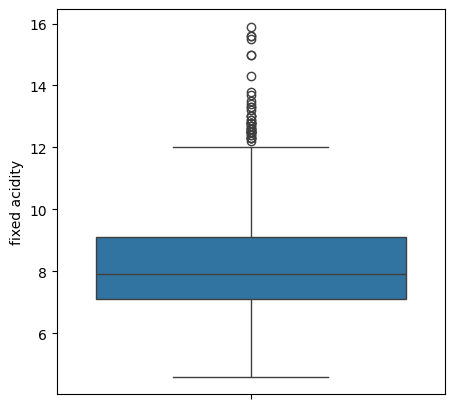

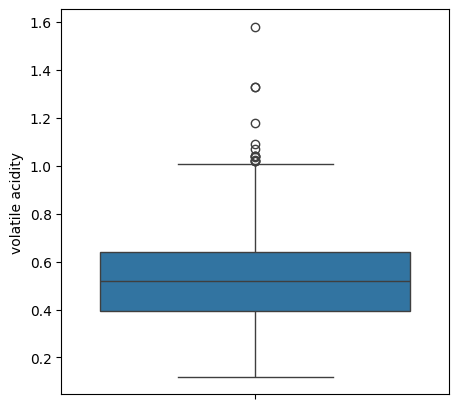

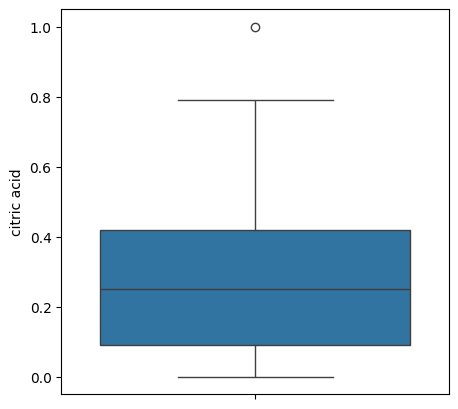

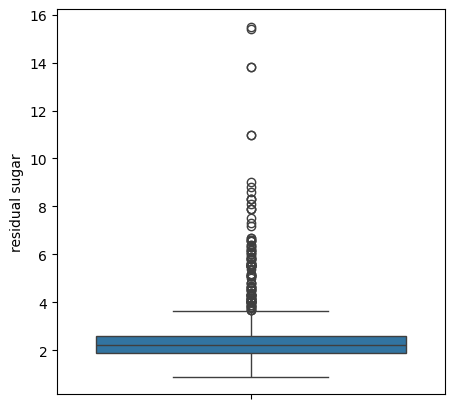

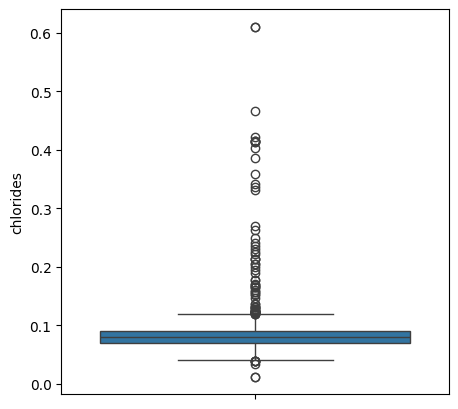

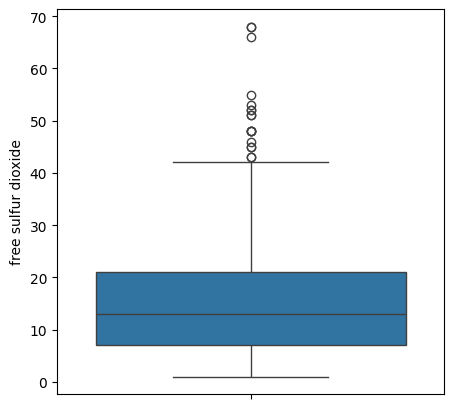

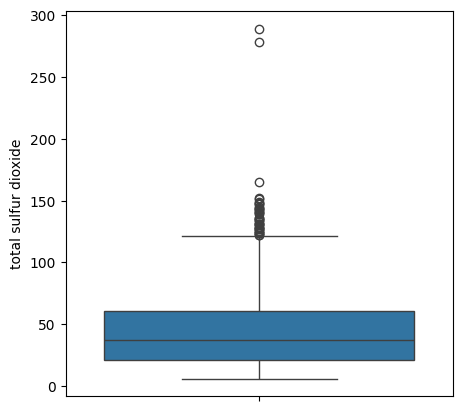

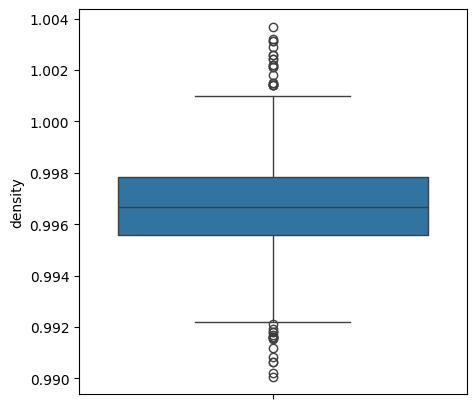

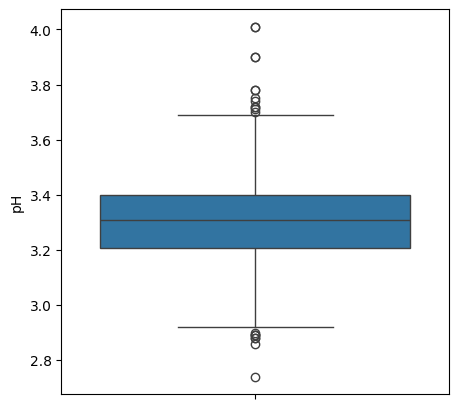

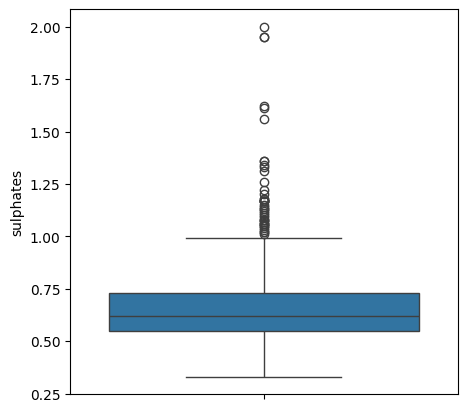

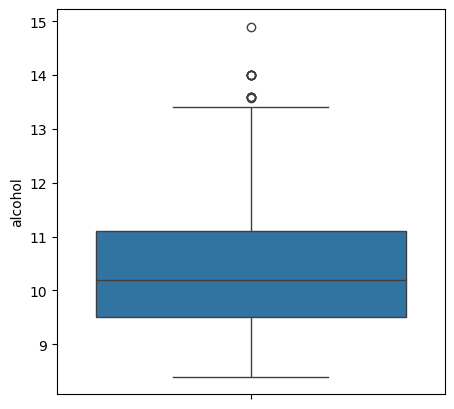

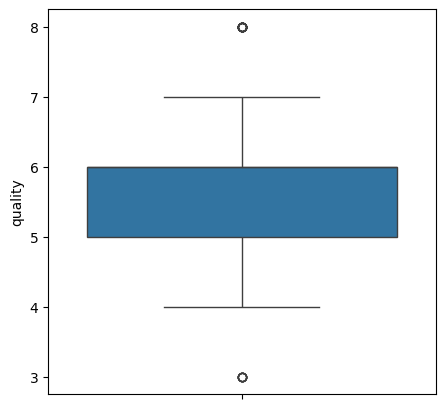

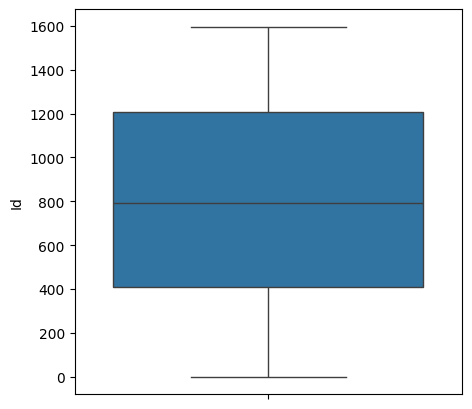

In [11]:
for col in num_col:
  plt.figure(figsize=(5,5))
  sns.boxplot(df[col])
  plt.show()

In [12]:
for col in num_col:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

  print(f"Outliers in {col} removed")

Outliers in fixed acidity removed
Outliers in volatile acidity removed
Outliers in citric acid removed
Outliers in residual sugar removed
Outliers in chlorides removed
Outliers in free sulfur dioxide removed
Outliers in total sulfur dioxide removed
Outliers in density removed
Outliers in pH removed
Outliers in sulphates removed
Outliers in alcohol removed
Outliers in quality removed
Outliers in Id removed


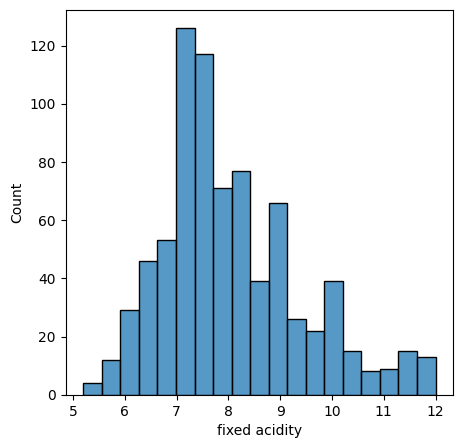

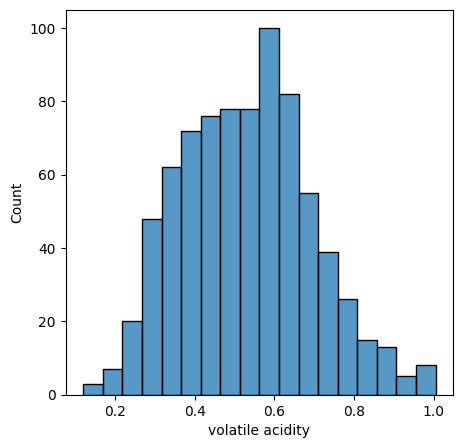

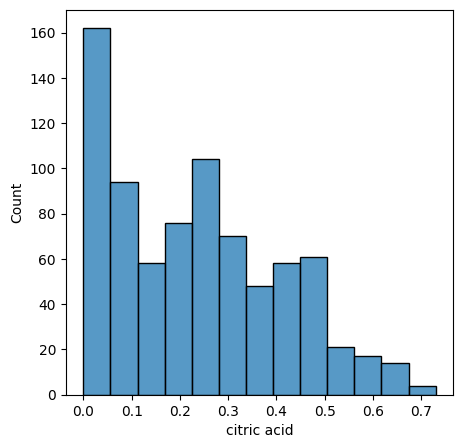

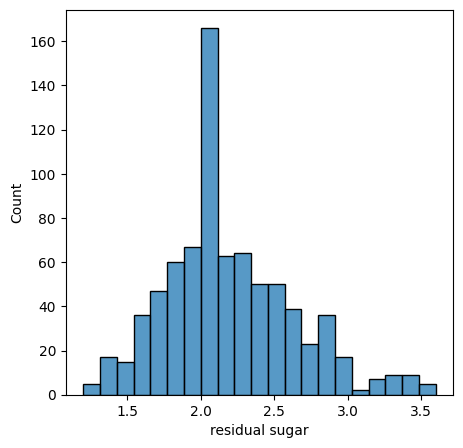

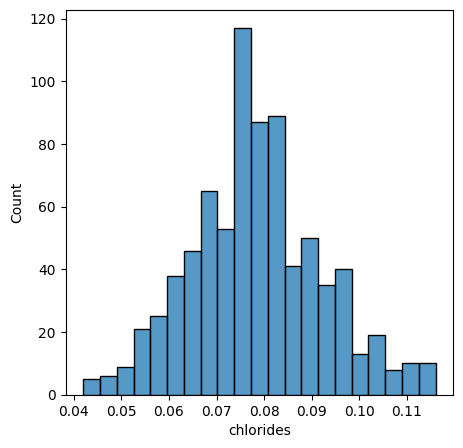

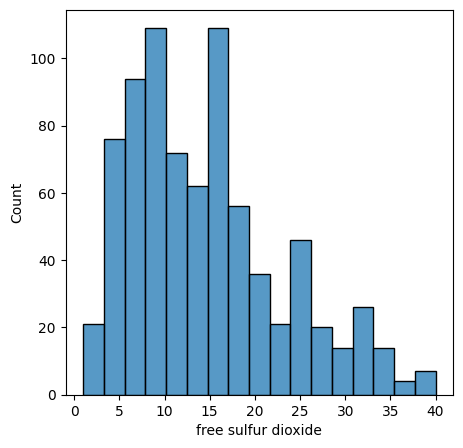

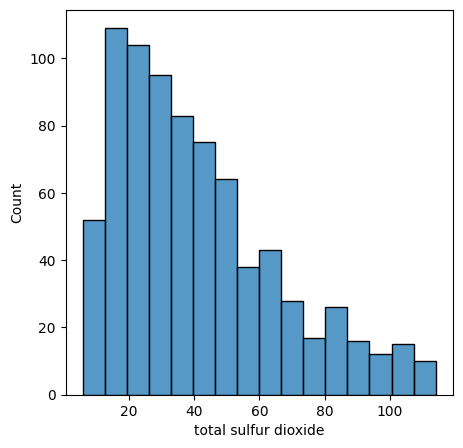

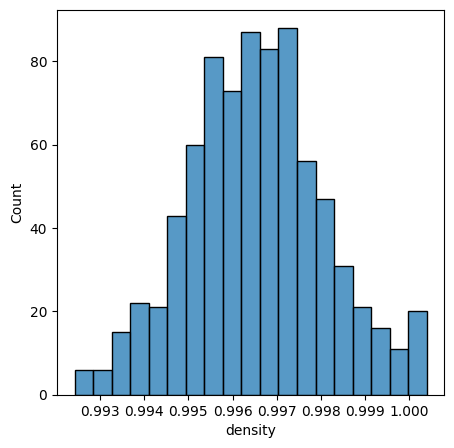

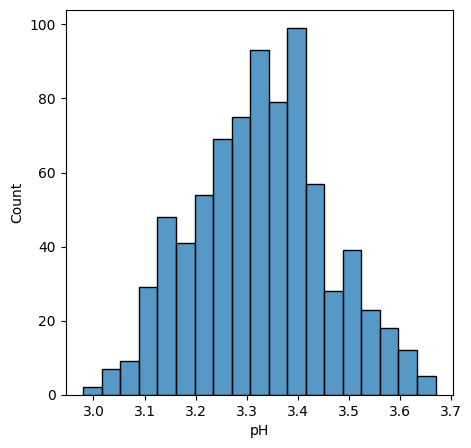

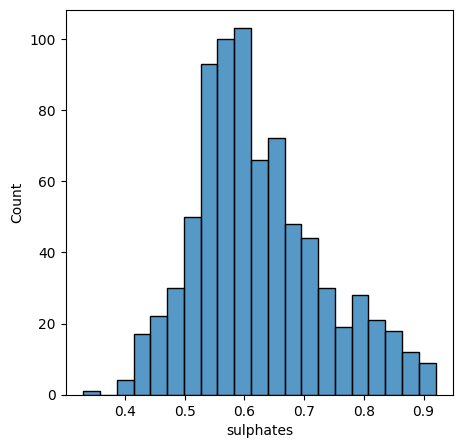

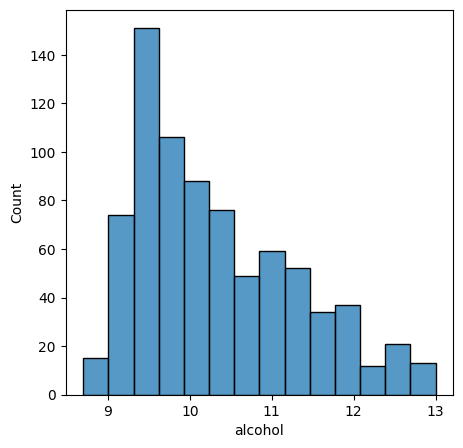

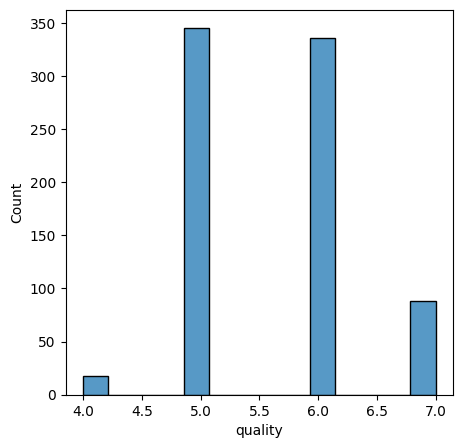

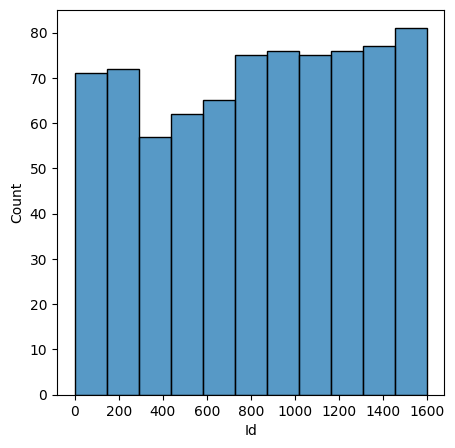

In [13]:
# Univariate analysis
for col in num_col:
  plt.figure(figsize=(5,5))
  sns.histplot(df[col])
  plt.show()

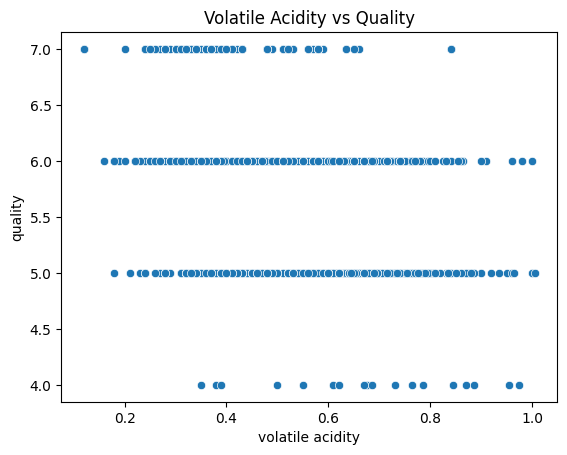

In [15]:
sns.scatterplot(x='volatile acidity', y='quality', data=df)
plt.title('Volatile Acidity vs Quality')
plt.show()

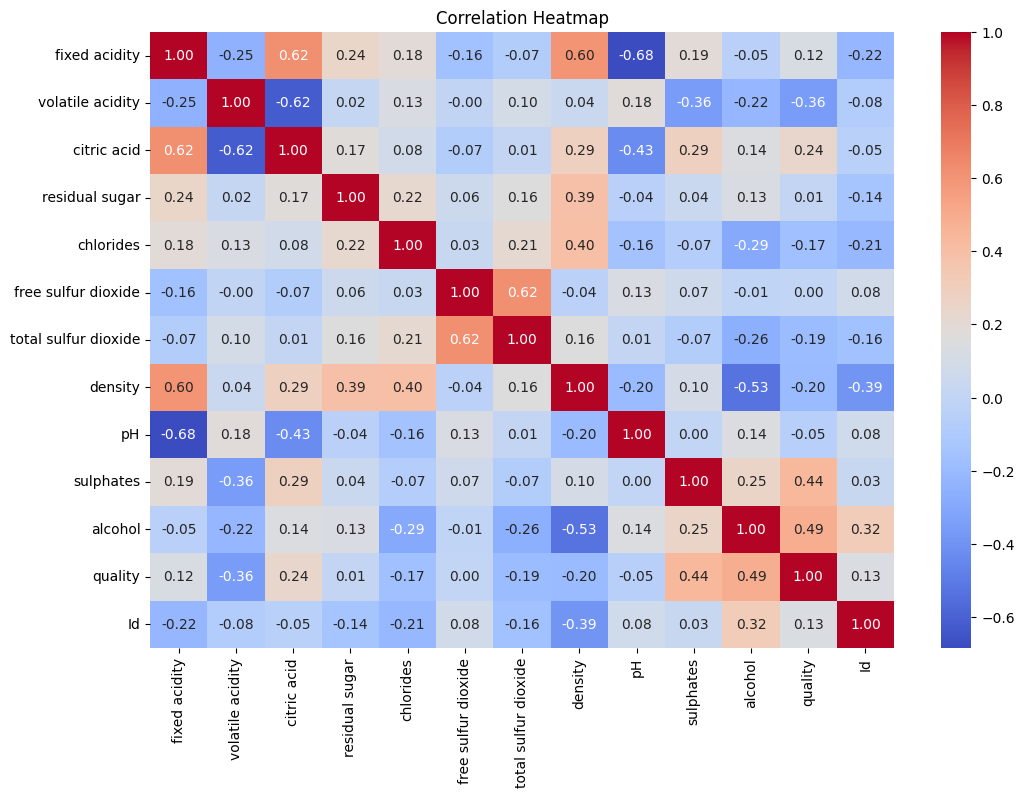

In [16]:
# Correlation Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [17]:
X = df.drop('quality', axis=1)
y = df['quality']

In [18]:
print(X.shape)
print(y.shape)

(787, 12)
(787,)


In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [21]:
model = AdaBoostClassifier(
    n_estimators=100,
    random_state=42,
    learning_rate = 1.0
)

In [22]:
model.fit(X_train, y_train)

AdaBoostClassifier(n_estimators=100, random_state=42)

In [23]:
y_pred = model.predict(X_test)
print(y_pred)

[6 5 5 6 6 6 6 5 4 5 5 6 5 6 6 6 6 5 6 5 6 5 7 5 5 6 6 6 6 6 6 6 7 7 5 5 7
 6 5 6 6 5 6 5 5 6 5 6 5 5 6 6 5 6 5 6 7 7 5 5 6 7 6 7 5 6 5 6 7 6 5 5 6 5
 7 6 6 6 6 6 5 5 6 6 5 6 6 5 5 6 6 5 6 4 5 6 7 7 5 6 6 6 6 7 6 5 5 5 5 5 5
 5 5 5 6 6 5 7 5 5 6 6 5 5 6 4 5 5 6 5 7 5 6 5 5 5 6 5 5 5 5 5 7 5 6 7 7 5
 5 5 5 7 5 6 5 5 6 5]


In [24]:
print("Training accuracy:", model.score(X_train, y_train))
print("Testing accuracy:", model.score(X_test, y_test))

Training accuracy: 0.5707472178060413
Testing accuracy: 0.5822784810126582


In [25]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [26]:
print("Training accuracy:", rf.score(X_train, y_train))
print("Testing accuracy:", rf.score(X_test, y_test))

Training accuracy: 1.0
Testing accuracy: 0.6772151898734177


In [27]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [50, 100,200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200, 300]},
             scoring='accuracy')

In [28]:
print("Training Accuracy Score:", grid_search.score(X_train, y_train))
print("Testing Accuracy Score:", grid_search.score(X_test, y_test))

Training Accuracy Score: 0.9507154213036566
Testing Accuracy Score: 0.6772151898734177
